# Data Integration and PCA

In [69]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

In [70]:
acs = pd.read_csv("ACS_5-Year_Economic_Characteristics_DC_Census_Tract.csv") 
acs.head()

,OBJECTID,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME,NAMELSAD,MTFCC,FUNCSTAT,...,DP03_0132PE,DP03_0133PE,DP03_0134PE,DP03_0135PE,DP03_0136PE,DP03_0137PE,SE_ANNO_CAD_DATA,GLOBALID,SHAPEAREA,SHAPELEN
0,1,11,1,5302,11001005302,1400000US11001005302,53.02,Census Tract 53.02,G5020,S,...,0.0,1.5,1.1,3.9,2.0,1.6,NaN,{8D441CA5-6D45-438E-A5F2-61AC35F36BA0},0,0
1,2,11,1,4402,11001004402,1400000US11001004402,44.02,Census Tract 44.02,G5020,S,...,54.4,7.2,5.3,25.4,9.7,8.0,NaN,{1C63F779-6D51-4833-9398-C0EAAD6A134C},0,0
2,3,11,1,10602,11001010602,1400000US11001010602,106.02,Census Tract 106.02,G5020,S,...,41.3,12.4,11.6,22.2,12.4,15.4,NaN,{B68F4A9D-7AD5-4265-A56C-C8DB9F04A596},0,0
3,4,11,1,804,11001000804,1400000US11001000804,8.04,Census Tract 8.04,G5020,S,...,0.0,3.6,2.3,7.7,1.0,10.7,NaN,{91534B3F-F409-4BF1-B676-DB8D9B5CD13E},0,0
4,5,11,1,3902,11001003902,1400000US11001003902,39.02,Census Tract 39.02,G5020,S,...,0.0,6.7,3.1,27.7,0.0,10.2,NaN,{A633B310-4F16-473E-88B3-F09B4F323DE6},0,0


### Counting crime points in each census tract and adding those points on a polygon data using spatial join. 
#### The next codes have been adopted from DC_Crime_CensusTract_SpatialJoin.ipynb by Professor Park

In [71]:
tracts = gpd.read_file('Census_Tracts_in_2020.shp')
tracts = tracts[['GEOID', 'TRACT', 'NAME', 'geometry']].copy()
tracts = tracts.to_crs('EPSG:4326')

tracts.head()

,GEOID,TRACT,NAME,geometry
0,11001002002,002002,Census Tract 20.02,"POLYGON ((-77.03642 38.94975, -77.03642 38.950..."
1,11001002101,002101,Census Tract 21.01,"POLYGON ((-77.02824 38.95813, -77.02824 38.958..."
2,11001002102,002102,Census Tract 21.02,"POLYGON ((-77.01997 38.95819, -77.01997 38.958..."
3,11001002201,002201,Census Tract 22.01,"POLYGON ((-77.02743 38.95188, -77.02727 38.951..."
4,11001002202,002202,Census Tract 22.02,"POLYGON ((-77.01968 38.95209, -77.01958 38.952..."


In [72]:
crime = pd.read_csv("./Crime_Incidents_in_2025.csv")
crime = crime.dropna(subset=['LONGITUDE', 'LATITUDE'])

crime[['OFFENSE', 'LONGITUDE', 'LATITUDE']].head()

,OFFENSE,LONGITUDE,LATITUDE
0,HOMICIDE,-76.934478,38.888528
1,HOMICIDE,-76.993222,38.833020
2,HOMICIDE,-77.000574,38.842411
3,HOMICIDE,-76.921301,38.892670
4,MOTOR VEHICLE THEFT,-76.950398,38.863721


<Axes: >

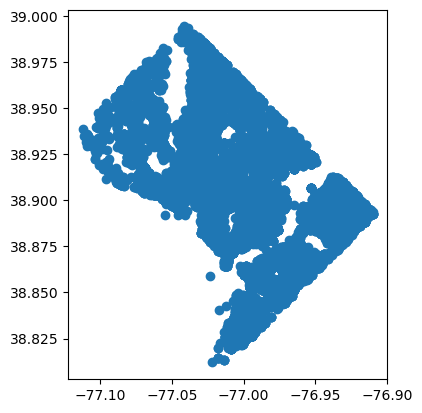

In [73]:
crime_points = gpd.GeoDataFrame(
    crime,
    geometry=gpd.points_from_xy(crime['LONGITUDE'], crime['LATITUDE']),
    crs='EPSG:4326'
)
crime_points.plot()

In [74]:
joined = gpd.sjoin(
    crime_points,
    tracts[['GEOID', 'geometry']],
    how='inner',
    predicate='within'
)

joined[['OFFENSE', 'GEOID']].head()

,OFFENSE,GEOID
0,HOMICIDE,11001009906
1,HOMICIDE,11001009801
2,HOMICIDE,11001009804
3,HOMICIDE,11001007808
4,MOTOR VEHICLE THEFT,11001007603


In [75]:
crime_counts = joined.groupby('GEOID').size()
crime_counts = crime_counts.reset_index(name='crime_n')

tracts_with_crime = tracts.merge(crime_counts, on='GEOID', how='left')
tracts_with_crime['crime_n'] = tracts_with_crime['crime_n'].fillna(0).astype(int)

tracts_with_crime[['GEOID', 'NAME', 'crime_n']].head()

,GEOID,NAME,crime_n
0,11001002002,Census Tract 20.02,85
1,11001002101,Census Tract 21.01,174
2,11001002102,Census Tract 21.02,104
3,11001002201,Census Tract 22.01,54
4,11001002202,Census Tract 22.02,78


In [76]:
offense_counts = pd.crosstab(
    joined['GEOID'],
    joined['OFFENSE'].fillna('UNKNOWN')
)

offense_counts.head()

OFFENSE,ARSON,ASSAULT W/DANGEROUS WEAPON,BURGLARY,HOMICIDE,MOTOR VEHICLE THEFT,ROBBERY,SEX ABUSE,THEFT F/AUTO,THEFT/OTHER
GEOID,,,,,,,,,
11001000101,0,0,0,0,1,1,0,5,11
11001000102,0,0,1,0,17,1,1,64,164
11001000201,0,0,1,0,1,0,0,2,8
11001000202,0,3,3,0,9,1,0,96,230
11001000300,0,2,1,0,3,2,0,8,47


In [77]:
offense_counts = offense_counts.rename(columns={
    'ARSON': 'arson_n',
    'ASSAULT W/DANGEROUS WEAPON': 'assault_n',
    'BURGLARY': 'burglary_n',
    'HOMICIDE': 'homicide_n',
    'MOTOR VEHICLE THEFT': 'mv_theft_n',
    'ROBBERY': 'robbery_n',
    'SEX ABUSE': 'sexabuse_n',
    'THEFT F/AUTO': 'theftcar_n',
    'THEFT/OTHER': 'theftoth_n',
    'UNKNOWN': 'unknown_n'
})

# Keep this list to select all offense-count columns together.
offense_columns = offense_counts.columns.tolist()
offense_counts = offense_counts.reset_index()

offense_counts.head()

OFFENSE,GEOID,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,robbery_n,sexabuse_n,theftcar_n,theftoth_n
0,11001000101,0,0,0,0,1,1,0,5,11
1,11001000102,0,0,1,0,17,1,1,64,164
2,11001000201,0,0,1,0,1,0,0,2,8
3,11001000202,0,3,3,0,9,1,0,96,230
4,11001000300,0,2,1,0,3,2,0,8,47


In [78]:
tracts_with_crime = tracts_with_crime.merge(
    offense_counts,
    on='GEOID',
    how='left'
)

tracts_with_crime[offense_columns] = (
    tracts_with_crime[offense_columns].fillna(0).astype(int)
)

tracts_with_crime.drop(columns=['geometry']).head()

,GEOID,TRACT,NAME,crime_n,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,robbery_n,sexabuse_n,theftcar_n,theftoth_n
0,11001002002,002002,Census Tract 20.02,85,0,6,2,0,26,6,0,20,25
1,11001002101,002101,Census Tract 21.01,174,0,11,11,0,28,9,0,28,87
2,11001002102,002102,Census Tract 21.02,104,0,6,2,0,32,3,0,36,25
3,11001002201,002201,Census Tract 22.01,54,0,1,0,0,16,4,0,14,19
4,11001002202,002202,Census Tract 22.02,78,0,6,0,0,28,2,1,17,24


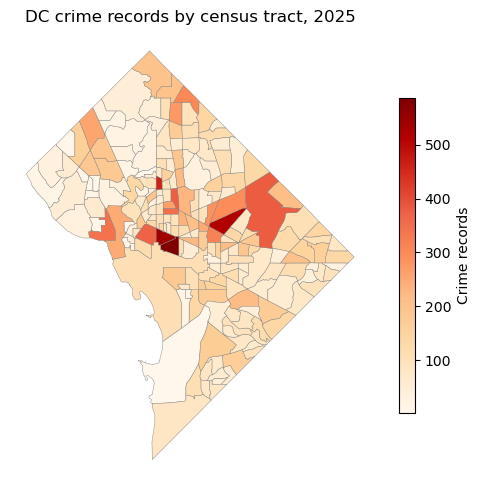

In [79]:
fig, ax = plt.subplots(figsize=(6, 5))

tracts_with_crime.plot(
    column='crime_n',
    cmap='OrRd',
    edgecolor='grey',
    linewidth=0.3,
    legend=True,
    legend_kwds={'label': 'Crime records', 'shrink': 0.7},
    ax=ax
)

ax.set_title('DC crime records by census tract, 2025')
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [80]:
output_folder = Path('output/simple_4326')
output_folder.mkdir(parents=True, exist_ok=True)

tracts_with_crime.to_file(
    output_folder / 'dc_tracts_crime_2025.shp',
    driver='ESRI Shapefile',
    index=False
)

tracts_with_crime.drop(columns=['geometry']).to_csv(
    output_folder / 'dc_tract_crime_counts_2025.csv',
    index=False
)

### From here, merging the supplementary dataset with tracts_with_crime.
#### One issue that kept coming up was that the data woud not merge on GEOID due to tracts['GEOID'] being a string and acs['GEOID'] being an integer. Hence, converging acs['GEOID'] to a string to match tracts['GEOID'] here: 

In [85]:
acs['GEOID'] = acs['GEOID'].astype(str)

#### Then merge acs dataset with tracts_with_crime dataset. The connecting identifier is 'GEOID'.

In [86]:
dc = tracts_with_crime.merge(acs, on='GEOID', how='left', suffixes=('', '_acs'))
dc.head()

,GEOID,TRACT,NAME,geometry,crime_n,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,...,DP03_0132PE,DP03_0133PE,DP03_0134PE,DP03_0135PE,DP03_0136PE,DP03_0137PE,SE_ANNO_CAD_DATA,GLOBALID,SHAPEAREA,SHAPELEN
0,11001002002,002002,Census Tract 20.02,"POLYGON ((-77.03642 38.94975, -77.03642 38.950...",85,0,6,2,0,26,...,0.0,6.8,6.9,6.3,4.6,8.1,NaN,{A6F5F313-DE0B-47D9-96D0-FC1337BF288C},0,0
1,11001002101,002101,Census Tract 21.01,"POLYGON ((-77.02824 38.95813, -77.02824 38.958...",174,0,11,11,0,28,...,2.6,6.5,5.3,12.5,4.0,7.8,NaN,{E6D4A023-9C0F-432E-BC5F-A2A7FEF89C02},0,0
2,11001002102,002102,Census Tract 21.02,"POLYGON ((-77.01997 38.95819, -77.01997 38.958...",104,0,6,2,0,32,...,3.0,14.1,15.0,9.1,3.7,32.4,NaN,{79FBE5B5-3641-45D3-ACB2-E8767E0FE148},0,0
3,11001002201,002201,Census Tract 22.01,"POLYGON ((-77.02743 38.95188, -77.02727 38.951...",54,0,1,0,0,16,...,0.0,1.2,0.6,4.0,0.0,4.5,NaN,{27CBE22E-F304-4643-8E5E-8615C12E7688},0,0
4,11001002202,002202,Census Tract 22.02,"POLYGON ((-77.01968 38.95209, -77.01958 38.952...",78,0,6,0,0,28,...,54.2,11.5,11.6,11.1,27.9,13.4,NaN,{8D46BB44-2F84-46A0-A5F1-2F69E7AD5BA6},0,0


#### Renamed relevant variables for convinience.

In [93]:
dc = dc.rename(columns={'DP03_0001E':  'employment', 'DP03_0063E':  'mean_income', 'DP03_0133PE': 'povertylvl'})
dc.head()

,GEOID,TRACT,NAME,geometry,crime_n,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,...,DP03_0132PE,povertylvl,DP03_0134PE,DP03_0135PE,DP03_0136PE,DP03_0137PE,SE_ANNO_CAD_DATA,GLOBALID,SHAPEAREA,SHAPELEN
0,11001002002,002002,Census Tract 20.02,"POLYGON ((-77.03642 38.94975, -77.03642 38.950...",85,0,6,2,0,26,...,0.0,6.8,6.9,6.3,4.6,8.1,NaN,{A6F5F313-DE0B-47D9-96D0-FC1337BF288C},0,0
1,11001002101,002101,Census Tract 21.01,"POLYGON ((-77.02824 38.95813, -77.02824 38.958...",174,0,11,11,0,28,...,2.6,6.5,5.3,12.5,4.0,7.8,NaN,{E6D4A023-9C0F-432E-BC5F-A2A7FEF89C02},0,0
2,11001002102,002102,Census Tract 21.02,"POLYGON ((-77.01997 38.95819, -77.01997 38.958...",104,0,6,2,0,32,...,3.0,14.1,15.0,9.1,3.7,32.4,NaN,{79FBE5B5-3641-45D3-ACB2-E8767E0FE148},0,0
3,11001002201,002201,Census Tract 22.01,"POLYGON ((-77.02743 38.95188, -77.02727 38.951...",54,0,1,0,0,16,...,0.0,1.2,0.6,4.0,0.0,4.5,NaN,{27CBE22E-F304-4643-8E5E-8615C12E7688},0,0
4,11001002202,002202,Census Tract 22.02,"POLYGON ((-77.01968 38.95209, -77.01958 38.952...",78,0,6,0,0,28,...,54.2,11.5,11.6,11.1,27.9,13.4,NaN,{8D46BB44-2F84-46A0-A5F1-2F69E7AD5BA6},0,0


#### Checking if there is any row or missing value in the merged dataset dc, and if the 'GEOID' column is unique.

In [97]:
print("tracts:", len(tracts), "merged _rows:", len(dc)) # should match the numebr
for col in ['employment', 'mean_income', 'povertylvl']:
    print(col, "missing:", dc[col].isna().sum())
print("GEOID unique:", dc['GEOID'].is_unique)

tracts: 206 merged _rows: 206
employment missing: 0
mean_income missing: 0
povertylvl missing: 0
GEOID unique: True


#### Created two new columns, grouping crimes into two categories: violent crimes and property crimes

In [107]:
dc['violent_n']  = dc[['homicide_n', 'robbery_n', 'assault_n', 'sexabuse_n']].sum(axis=1)
dc['property_n'] = dc[['burglary_n', 'mv_theft_n', 'theftcar_n', 'theftoth_n']].sum(axis=1)
dc.head()

,GEOID,TRACT,NAME,geometry,crime_n,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,...,DP03_0134PE,DP03_0135PE,DP03_0136PE,DP03_0137PE,SE_ANNO_CAD_DATA,GLOBALID,SHAPEAREA,SHAPELEN,violent_n,property_n
0,11001002002,002002,Census Tract 20.02,"POLYGON ((-77.03642 38.94975, -77.03642 38.950...",85,0,6,2,0,26,...,6.9,6.3,4.6,8.1,NaN,{A6F5F313-DE0B-47D9-96D0-FC1337BF288C},0,0,12,73
1,11001002101,002101,Census Tract 21.01,"POLYGON ((-77.02824 38.95813, -77.02824 38.958...",174,0,11,11,0,28,...,5.3,12.5,4.0,7.8,NaN,{E6D4A023-9C0F-432E-BC5F-A2A7FEF89C02},0,0,20,154
2,11001002102,002102,Census Tract 21.02,"POLYGON ((-77.01997 38.95819, -77.01997 38.958...",104,0,6,2,0,32,...,15.0,9.1,3.7,32.4,NaN,{79FBE5B5-3641-45D3-ACB2-E8767E0FE148},0,0,9,95
3,11001002201,002201,Census Tract 22.01,"POLYGON ((-77.02743 38.95188, -77.02727 38.951...",54,0,1,0,0,16,...,0.6,4.0,0.0,4.5,NaN,{27CBE22E-F304-4643-8E5E-8615C12E7688},0,0,5,49
4,11001002202,002202,Census Tract 22.02,"POLYGON ((-77.01968 38.95209, -77.01958 38.952...",78,0,6,0,0,28,...,11.6,11.1,27.9,13.4,NaN,{8D46BB44-2F84-46A0-A5F1-2F69E7AD5BA6},0,0,9,69


#### The suitable varaibles we chose for PCA are: violent crime rate, property crime rate, mean household income, and employment. Since the datasets have been merged into one on GEOID, two categorized crime rates and socioeconomic characterstics are the relevant variables to find the patterns across areas. Variables for identification are only for labeling instances, therefore, excluded. Other income measures or employment measures have been excluded as well since they are highly correlated with the selected variables. Categorical variables with no numerical values have also been disregarded as they are not suitable for PCA

#### The variables that need standardization are: violent_n. property_n, mean_income, and 'povertylvl'. Because the units of these variables vary from tens to tens of thousands, it is hard to see the true pattern of the data. PCA needs sizes of variance to effectively handle dimensions, using directions.

In [108]:
from sklearn.preprocessing import StandardScaler
dc_st = StandardScaler().fit_transform(dc[['violent_n', 'property_n', 'mean_income', 'povertylvl']])
dc_st = pd.DataFrame(dc_st, columns = ['violent_n', 'property_n', 'mean_income', 'povertylvl'])
dc_st.head(10)

,violent_n,property_n,mean_income,povertylvl
0,0.000449,-0.350232,0.668944,-0.611793
1,0.740957,0.543752,-0.218589,-0.633510
2,-0.277241,-0.107422,-0.283575,-0.083353
3,-0.647495,-0.615116,0.415868,-1.017172
4,-0.277241,-0.394379,-0.488642,-0.271564
5,-1.017748,-0.968295,0.721654,-0.966499
6,-0.925185,1.559140,1.340339,-0.705899
7,-1.110312,-1.023479,-1.952235,6.134868
8,-0.740058,2.574529,1.333714,-0.076114
9,-0.740058,-0.504748,1.201890,-0.713138
